In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

# Works from either repository root or notebooks/.
HERE = Path.cwd()
REPO = HERE if (HERE / "experiments/matched_inference/evaluation").exists() else HERE.parent
assert (REPO / "experiments/matched_inference/evaluation").exists(), "Open Jupyter from repository root or notebooks/"
EVAL = REPO / "experiments/matched_inference/evaluation"
FIG = REPO / "experiments/matched_inference/figures"
FIG.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(EVAL / "matched_summary.csv")
field = pd.read_csv(EVAL / "matched_per_field.csv")
METHODS = ["qwen_vlm", "paddle_llm_p2", "regex_tesseract", "doctr_llm_p2", "tesseract_llm_p2", "tesseract_llm_p1", "openocr_llm_p2", "easyocr_llm_p2"]
NAMES = {"qwen_vlm":"Qwen-VLM", "paddle_llm_p2":"PaddleOCR + LLM P2", "regex_tesseract":"Regex + Tesseract", "doctr_llm_p2":"DocTR + LLM P2", "tesseract_llm_p2":"Tesseract + LLM P2", "tesseract_llm_p1":"Tesseract + LLM P1", "openocr_llm_p2":"OpenOCR + LLM P2", "easyocr_llm_p2":"EasyOCR + LLM P2"}
FIELDS = ["load_number", "pickup_location", "pickup_time", "dropoff_location", "dropoff_time", "total_rate", "rate_per_mile"]
FIELD_LABELS = ["Load number", "Pickup location", "Pickup time", "Dropoff location", "Dropoff time", "Total rate", "Rate per mile"]
assert len(summary)==8 and len(field)==56
assert set(summary.method)==set(METHODS)
assert not summary.duplicated('method').any()
assert not field.duplicated(['method','field']).any()
assert set(field.field)==set(FIELDS)
assert (summary.n==135).all()
plt.rcParams.update({'figure.dpi':125,'savefig.dpi':300,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})

def save_fig(fig, stem):
    for ext in ('pdf','png'):
        path = FIG / f'{stem}.{ext}'
        fig.savefig(path, bbox_inches='tight', dpi=300)
    print('Saved:', FIG / f'{stem}.pdf', 'and PNG')

def heatmap(data, title, cmap='YlGnBu', vmin=0, vmax=100, fmt='.1f', center=None):
    fig, ax = plt.subplots(figsize=(12,5.7))
    norm = TwoSlopeNorm(vmin=vmin,vcenter=center,vmax=vmax) if center is not None else None
    im=ax.imshow(data.values, aspect='auto', cmap=cmap, vmin=None if norm else vmin, vmax=None if norm else vmax, norm=norm)
    ax.set_xticks(range(len(data.columns)), [c.replace('_',' ').title() for c in data.columns], rotation=28, ha='right')
    ax.set_yticks(range(len(data.index)), [NAMES.get(i,i) for i in data.index])
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v=float(data.iloc[i,j]); ax.text(j,i,format(v,fmt),ha='center',va='center',fontsize=8,color='white' if (center is None and v>65) else 'black')
    fig.colorbar(im,ax=ax,label='Percentage (%)' if center is None else 'Percentage-point change')
    ax.set_title(title,pad=12)
    fig.tight_layout()
    return fig

def pivot_metric(condition, metric):
    return field.pivot(index='method',columns='field',values=f'{condition}_{metric}').reindex(index=METHODS,columns=FIELDS)


## Corrected comparison table

In [2]:
cols=['method','historical_clean_f1','matched_clean_f1','noisy_f1','delta_noisy_vs_matched_f1_pp']
table=summary[cols].sort_values('matched_clean_f1',ascending=False).copy()
table['method']=table['method'].map(NAMES)
table.columns=['Method','Historical clean F1','Matched clean F1','Noisy F1','Noisy − matched (pp)']
display(table.round(2).reset_index(drop=True))
table.to_csv(EVAL/'robustness_paper_table.csv',index=False,float_format='%.2f')
assert np.allclose(summary.noisy_f1-summary.matched_clean_f1,summary.delta_noisy_vs_matched_f1_pp,atol=.011)

,Method,Historical clean F1,Matched clean F1,Noisy F1,Noisy − matched (pp)
0,Qwen-VLM,72.20,81.48,79.97,-1.51
1,PaddleOCR + LLM P2,65.69,68.79,68.43,-0.36
2,Regex + Tesseract,52.41,51.12,42.17,-8.95
3,DocTR + LLM P2,44.79,48.72,44.81,-3.91
4,Tesseract + LLM P2,39.50,42.51,35.22,-7.29
5,OpenOCR + LLM P2,25.61,31.43,33.23,1.80
6,Tesseract + LLM P1,30.26,27.51,23.27,-4.24
7,EasyOCR + LLM P2,9.96,11.67,9.80,-1.87


Saved: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures/fig18_matched_clean_vs_noisy_f1.pdf and PNG


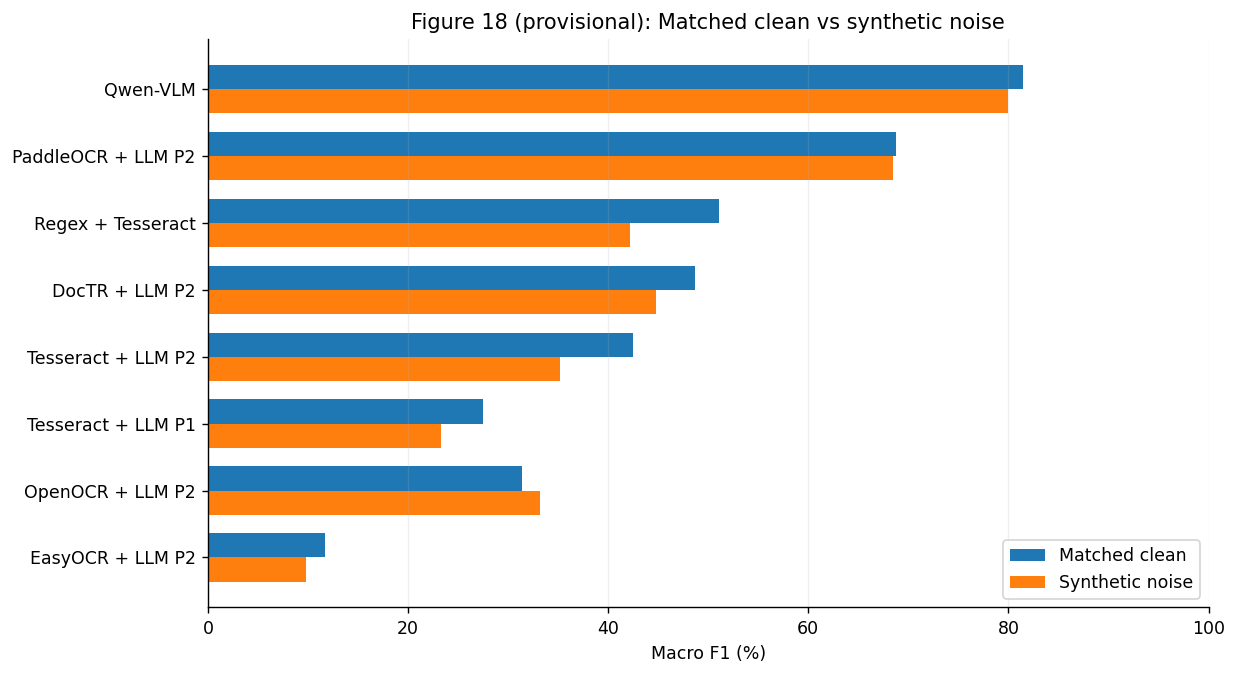

In [3]:
d=summary.set_index('method').reindex(METHODS)
y=np.arange(len(METHODS)); h=.36
fig,ax=plt.subplots(figsize=(10,5.5))
ax.barh(y-h/2,d.matched_clean_f1,height=h,label='Matched clean')
ax.barh(y+h/2,d.noisy_f1,height=h,label='Synthetic noise')
ax.set_yticks(y,[NAMES[m] for m in METHODS]); ax.invert_yaxis()
ax.set_xlim(0,100); ax.set_xlabel('Macro F1 (%)'); ax.set_title('Figure 18 (provisional): Matched clean vs synthetic noise')
ax.legend(loc='lower right'); ax.grid(axis='x',alpha=.2)
fig.tight_layout();save_fig(fig,'fig18_matched_clean_vs_noisy_f1');plt.show()

Saved: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures/fig19_noisy_field_f1.pdf and PNG


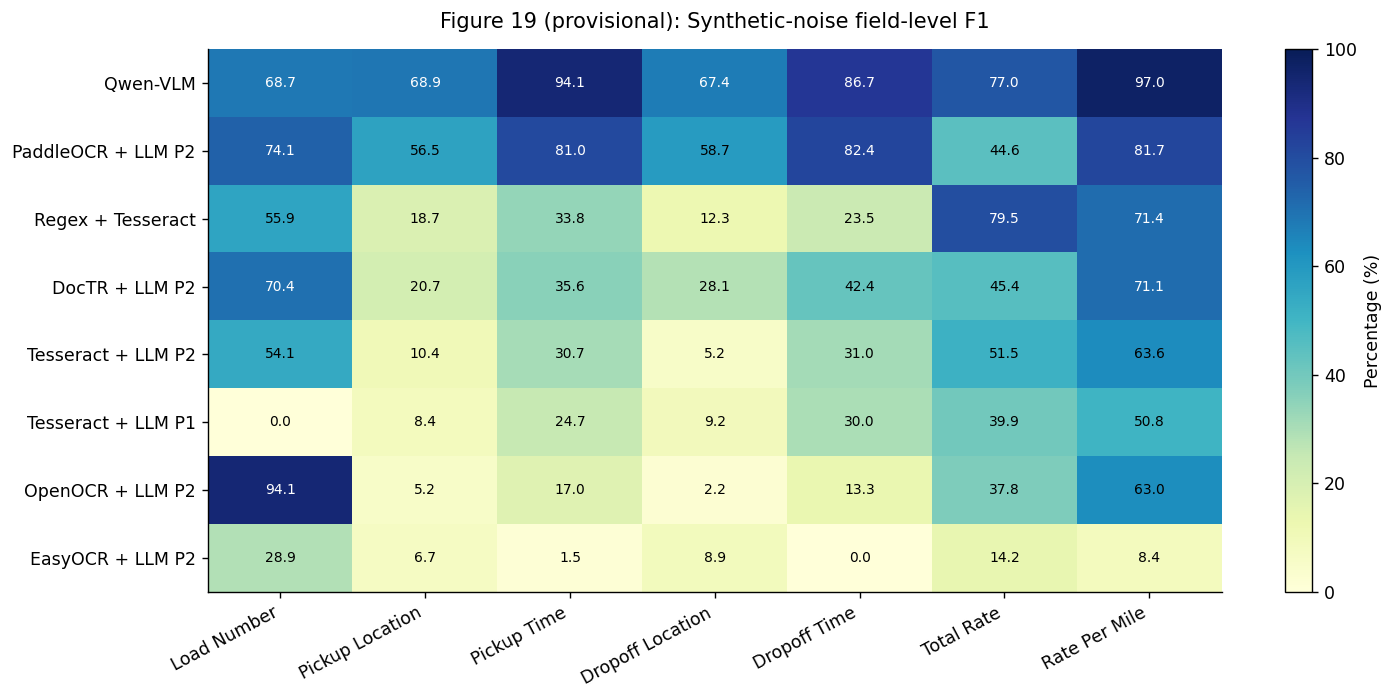

In [4]:
d=pivot_metric('noisy','f1')
fig=heatmap(d,'Figure 19 (provisional): Synthetic-noise field-level F1')
save_fig(fig,'fig19_noisy_field_f1');plt.show()

Saved: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures/fig20_matched_f1_delta.pdf and PNG


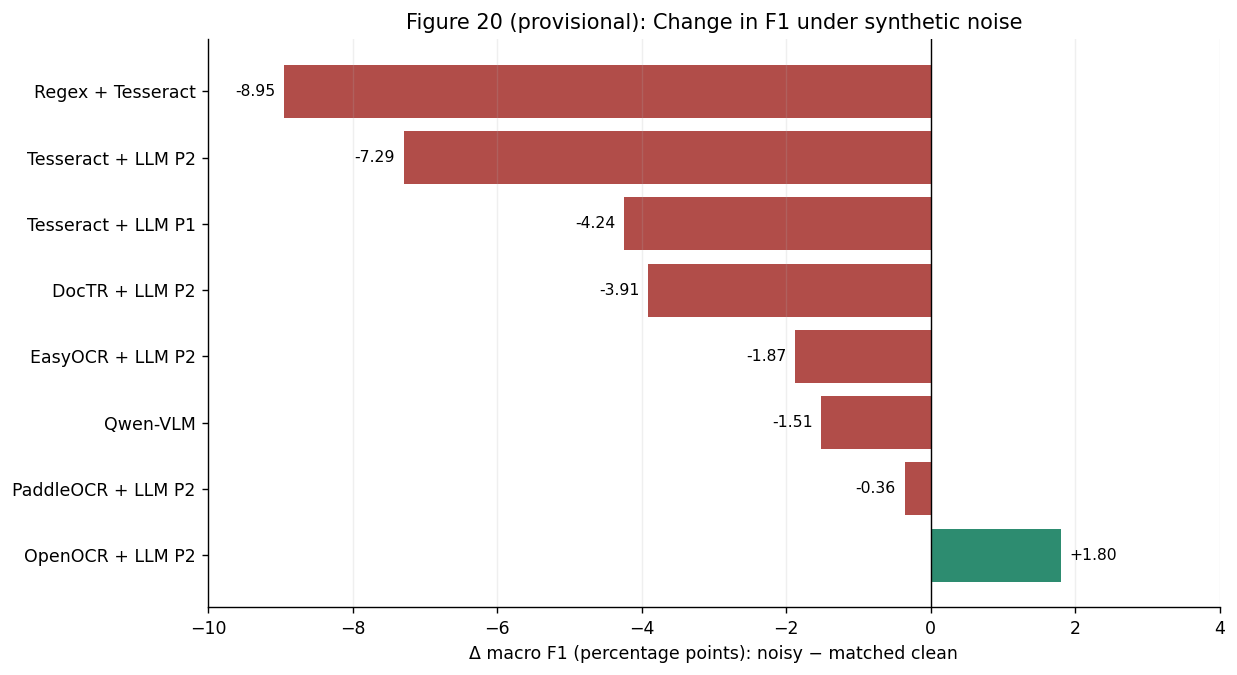

In [5]:
d=summary.set_index('method').reindex(METHODS).sort_values('delta_noisy_vs_matched_f1_pp')
vals=d.delta_noisy_vs_matched_f1_pp.values
y=np.arange(len(d))
fig,ax=plt.subplots(figsize=(10,5.5))
colors=['#b14d49' if v<0 else '#2d8c70' for v in vals]
ax.barh(y,vals,color=colors)
ax.set_yticks(y,[NAMES[m] for m in d.index]);ax.invert_yaxis()
ax.axvline(0,color='black',lw=.8);ax.set_xlabel('Δ macro F1 (percentage points): noisy − matched clean')
ax.set_title('Figure 20 (provisional): Change in F1 under synthetic noise')
for i,v in enumerate(vals):ax.text(v+(.12 if v>=0 else -.12),i,f'{v:+.2f}',va='center',ha='left' if v>=0 else 'right',fontsize=9)
ax.set_xlim(min(-10,vals.min()-1),max(4,vals.max()+1));ax.grid(axis='x',alpha=.2)
fig.tight_layout();save_fig(fig,'fig20_matched_f1_delta');plt.show()

field,load_number,pickup_location,pickup_time,dropoff_location,dropoff_time,total_rate,rate_per_mile
method,,,,,,,
qwen_vlm,-1.04,-2.96,0.39,-5.93,0.42,0.00,-1.48
paddle_llm_p2,-5.19,5.39,-2.66,2.44,-3.53,2.23,-1.19
regex_tesseract,-14.47,-3.29,-11.12,0.96,-23.54,-3.72,-7.49
doctr_llm_p2,12.59,4.44,-20.74,0.64,-19.10,1.49,-6.67
tesseract_llm_p2,-17.08,0.00,-11.08,-0.76,-16.50,-0.55,-5.04
tesseract_llm_p1,0.00,-1.36,-8.38,-0.62,-14.75,0.15,-4.76
openocr_llm_p2,0.00,2.22,6.67,0.00,6.67,2.22,-5.19
easyocr_llm_p2,-13.33,-1.46,0.75,2.22,0.00,2.20,-3.45


Saved: /root/lorex-ocr-llm-experiments/experiments/matched_inference/figures/supp_matched_per_field_f1_delta.pdf and PNG


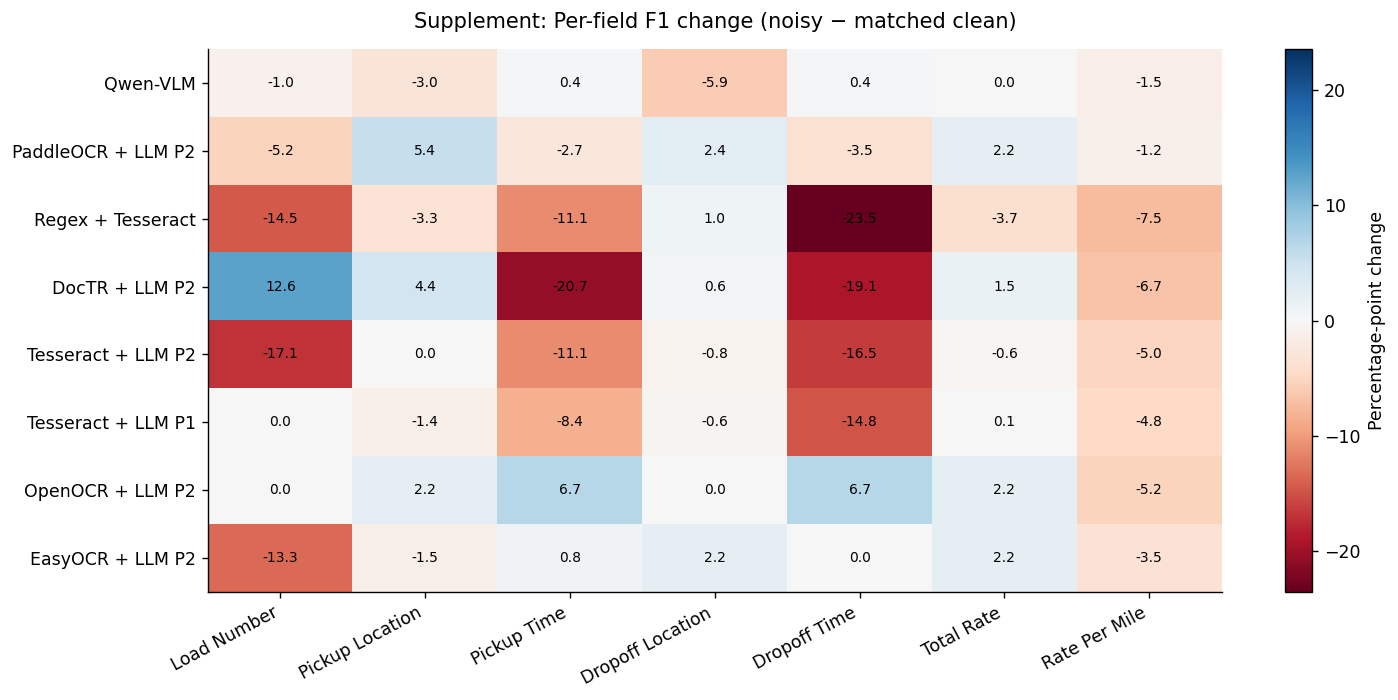

In [6]:
delta=field.pivot(index='method',columns='field',values='delta_noisy_vs_matched_f1_pp').reindex(index=METHODS,columns=FIELDS)
display(delta.round(2))
lim=max(1,float(np.abs(delta.to_numpy()).max()))
fig=heatmap(delta,'Supplement: Per-field F1 change (noisy − matched clean)',cmap='RdBu',vmin=-lim,vmax=lim,center=0)
save_fig(fig,'supp_matched_per_field_f1_delta');plt.show()
delta.to_csv(EVAL/'matched_field_f1_delta_table.csv',float_format='%.2f')

In [7]:
diag=summary[['method','historical_clean_f1','matched_clean_f1','noisy_f1']].copy()
diag['matched_minus_historical_pp']=diag.matched_clean_f1-diag.historical_clean_f1
diag=diag.sort_values('matched_minus_historical_pp',ascending=False)
diag['method']=diag['method'].map(NAMES)
display(diag.round(2))
diag.to_csv(EVAL/'historical_vs_matched_diagnostic.csv',index=False,float_format='%.2f')

,method,historical_clean_f1,matched_clean_f1,noisy_f1,matched_minus_historical_pp
7,Qwen-VLM,72.20,81.48,79.97,9.28
6,OpenOCR + LLM P2,25.61,31.43,33.23,5.82
5,DocTR + LLM P2,44.79,48.72,44.81,3.93
3,PaddleOCR + LLM P2,65.69,68.79,68.43,3.10
2,Tesseract + LLM P2,39.50,42.51,35.22,3.01
4,EasyOCR + LLM P2,9.96,11.67,9.80,1.71
0,Regex + Tesseract,52.41,51.12,42.17,-1.29
1,Tesseract + LLM P1,30.26,27.51,23.27,-2.75
